In [5]:
import meshio
import pyvista as pv
import matplotlib.pyplot as plt
import vtk
import numpy as np

input_mesh_folder = "../../../Data/data/meshes/"
output_folder = "../../build/Splat_surface_reconstruction_3/"
output_mesh_filepath = output_folder + "mesh.obj"
output_splat_sizes_filepath = output_folder + "splat_sizes.txt"

#input_mesh_name = "elephant.off"
input_mesh_name = "three_peaks.off"
#input_mesh_name = "pig.off"
input_mesh_filepath = input_mesh_folder + input_mesh_name

scale = 1.0

recompute_point_cloud = True

In [3]:
def poisson_sample_surface(mesh, d: float, seed=42):
    """
    Approximately Poisson-disk sample a triangle mesh surface.

    Samples lie on triangle faces, with minimum spacing approximately d.
    Returns sampled points and interpolated vertex normals.
    """
    if d <= 0:
        raise ValueError("d must be positive")

    mesh_min_x = np.min(np.asarray(mesh.points)[:, 0])
    mesh_min_y = np.min(np.asarray(mesh.points)[:, 1])
    mesh_min_z = np.min(np.asarray(mesh.points)[:, 2])

    mesh_max_x = np.max(np.asarray(mesh.points)[:, 0])
    mesh_max_y = np.max(np.asarray(mesh.points)[:, 1])
    mesh_max_z = np.max(np.asarray(mesh.points)[:, 2])

    max_diff = max(
        mesh_max_x - mesh_min_x,
        mesh_max_y - mesh_min_y,
        mesh_max_z - mesh_min_z
    )

    d = d * max_diff

    mesh = mesh.extract_surface().triangulate()
    mesh = mesh.compute_normals(
        point_normals=True,
        cell_normals=False,
        consistent_normals=True,
        auto_orient_normals=True,
    )

    vertices = np.asarray(mesh.points)
    vertex_normals = np.asarray(mesh.point_data["Normals"])

    # Extract triangle vertex indices.
    faces = np.asarray(mesh.faces).reshape(-1, 4)
    if not np.all(faces[:, 0] == 3):
        raise ValueError("Expected a triangulated mesh")
    triangles = faces[:, 1:]

    tri = vertices[triangles]
    cross = np.cross(tri[:, 1] - tri[:, 0],
                     tri[:, 2] - tri[:, 0])
    areas = 0.5 * np.linalg.norm(cross, axis=1)

    valid = areas > 1e-15
    triangles = triangles[valid]
    areas = areas[valid]

    if len(areas) == 0:
        raise ValueError("Mesh contains no non-degenerate triangles")

    # Triangle selection probabilities proportional to area.
    probabilities = areas / areas.sum()
    rng = np.random.default_rng(seed)

    # Spatial hash: cells have side length d / sqrt(3).
    # Neighboring cells within the minimum-distance radius are checked.
    cell_size = d / np.sqrt(3.0)
    neighbor_range = int(np.ceil(d / cell_size))
    grid = {}
    samples = []
    sample_normals = []

    def cell_key(p):
        return tuple(np.floor(p / cell_size).astype(int))

    def accept(p):
        key = cell_key(p)

        for dx in range(-neighbor_range, neighbor_range + 1):
            for dy in range(-neighbor_range, neighbor_range + 1):
                for dz in range(-neighbor_range, neighbor_range + 1):
                    bucket = grid.get(
                        (key[0] + dx, key[1] + dy, key[2] + dz), []
                    )
                    for idx in bucket:
                        if np.linalg.norm(samples[idx] - p) < d:
                            return False

        idx = len(samples)
        samples.append(p)
        grid.setdefault(key, []).append(idx)
        return True

    # Generate candidates uniformly over triangle areas.
    # Stop after a long run of rejected candidates.
    max_attempts = max(10000, len(vertices) * 100)
    failures = 0
    max_failures = max(5000, len(vertices) * 50)

    while failures < max_failures and len(samples) < max_attempts:
        ti = rng.choice(len(triangles), p=probabilities)
        ids = triangles[ti]
        a, b, c = vertices[ids]

        # Uniform random point in a triangle.
        u, v = rng.random(2)
        su = np.sqrt(u)
        bary = np.array([1 - su, su * (1 - v), su * v])
        p = bary @ np.array([a, b, c])

        if accept(p):
            # Interpolate the vertex normals using barycentric coordinates.
            n = bary @ vertex_normals[ids]
            norm = np.linalg.norm(n)

            if norm > 1e-15:
                sample_normals.append(n / norm)
            else:
                sample_normals.append(
                    cross[valid][ti] / np.linalg.norm(cross[valid][ti])
                )
            failures = 0
        else:
            failures += 1

    return np.asarray(samples), np.asarray(sample_normals)

def write_samples_off(points, normals, filename="samples.off"):
    points = np.asarray(points)
    normals = np.asarray(normals)

    assert points.shape == normals.shape
    assert points.ndim == 2 and points.shape[1] == 3

    with open(filename, "w") as f:
        f.write("OFF\n")
        f.write(f"{len(points)} 0 0\n")

        for p, n in zip(points, normals):
            f.write(
                f"{p[0]:.17g} {p[1]:.17g} {p[2]:.17g} "
                f"{n[0]:.17g} {n[1]:.17g} {n[2]:.17g}\n"
            )

In [4]:
mesh_data = meshio.read(input_mesh_filepath)
mesh_data_pv = pv.from_meshio(mesh_data)

if recompute_point_cloud:
    points, normals = poisson_sample_surface(mesh_data_pv, d=0.02)
    write_samples_off(points, normals, output_folder + "point_cloud002.off")

/tmp/ipykernel_69445/435120748.py:27: PyVistaFutureWarning: The default value of `algorithm` for the filter
`UnstructuredGrid.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  mesh = mesh.extract_surface().triangulate()


In [5]:

if recompute_point_cloud:
    # Convert the meshio mesh to PyVista
    mesh = pv.from_meshio(mesh_data).extract_surface().triangulate()

    # Convert sampled points to a PyVista point cloud
    points_cloud = pv.PolyData(np.asarray(points))

    # Display side by side
    plotter = pv.Plotter(shape=(1, 2))

    plotter.subplot(0, 0)
    plotter.add_text("Original mesh", font_size=12)
    plotter.add_mesh(mesh, color="lightblue", show_edges=True)

    plotter.subplot(0, 1)
    plotter.add_text("Poisson sampled points", font_size=12)
    plotter.add_mesh(
        mesh,
        color="lightgray",
        opacity=0.25,
    )
    plotter.add_mesh(
        points_cloud,
        color="red",
        point_size=5,
        render_points_as_spheres=True,
    )

    plotter.link_views()
    plotter.show()

/tmp/ipykernel_69445/3173406145.py:3: PyVistaFutureWarning: The default value of `algorithm` for the filter
`UnstructuredGrid.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  mesh = pv.from_meshio(mesh_data).extract_surface().triangulate()


Widget(value='<iframe src="http://localhost:46731/index.html?ui=P_0x7212dda6fe00_0&reconnect=auto" class="pyvi…

In [ ]:
# optionally run algorithm
%cd ../../build/Splat_surface_reconstruction_3
!ls
!./splat_reconstruction_function point_cloud.off {scale}

# back to the research/analysis directory
%cd ../../research/analysis
!ls

/home/milan/Git/cgal-public-dev/Splat_surface_reconstruction_3/build/Splat_surface_reconstruction_3
CMakeCache.txt		  mesh_debug.json
CMakeFiles		  mesh_debug_null_face.json
Makefile		  mesh_debug_wrong_orientation.json
cmake_install.cmake	  no_ear.json
invalid_orientation.json  no_ear_vertex_349.json
invalid_triangle.json	  point_cloud.off
involved_halfedge.json	  point_cloud002.off
iter1.json		  splat_reconstruction_function
iter2.json		  splat_sizes.txt
iter3.json		  splats.obj
mesh.obj		  splats_before.obj
mesh.ply		  splats_individual.obj
mesh.stl		  wrong_orientation.json
Filename: point_cloud.off
Centering and scaling point cloud between [-1,1]^3 ...
Average spacing: 0.0443564
Required edge length: 0.0443564
Estimating normals...
bbox: -1.04879,-0.758916,-0.90606 - 1.04879,0.758916,0.90606
Splat mesh written to splats_before.obj
Found 3 local points.
Found 4 local points.
Found 3 local points.
Found 3 local points.
Found 5 local points.
Found 3 local points.
Found 4 local points

: 

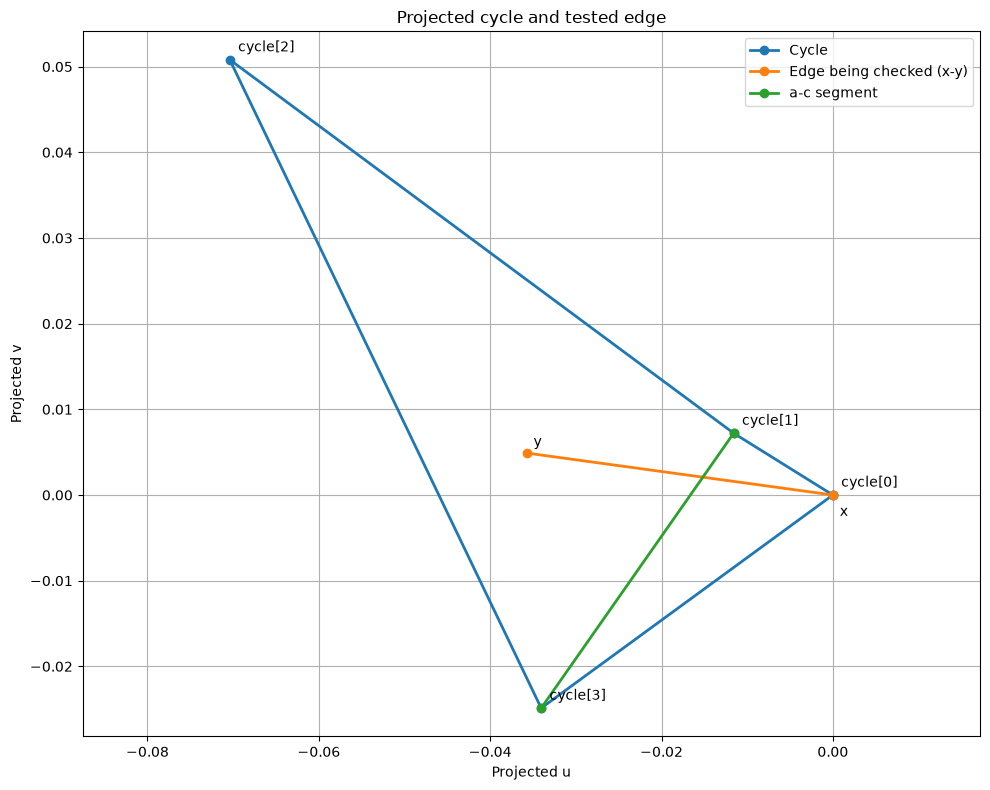

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def plot_projected_intersection(cycle_points, x, y, a, c):
    cycle = np.array(cycle_points, dtype=float)
    edge = np.array([x, y], dtype=float)
    ac = np.array([a, c], dtype=float)

    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot the closed cycle
    closed_cycle = np.vstack([cycle, cycle[0]])
    ax.plot(closed_cycle[:, 0], closed_cycle[:, 1], '-o',
            label="Cycle", linewidth=2)

    # Plot the edge being checked
    ax.plot(edge[:, 0], edge[:, 1], '-o',
            label="Edge being checked (x-y)", linewidth=2)

    # Plot the a-c segment
    ax.plot(ac[:, 0], ac[:, 1], '-o', label="a-c segment", linewidth=2)

    # Label cycle vertices
    for i, (px, py) in enumerate(cycle):
        ax.annotate(
            f"cycle[{i}]",
            (px, py),
            xytext=(6, 6),
            textcoords="offset points"
        )

    ax.annotate("x", edge[0], xytext=(5, -15),
                textcoords="offset points")
    ax.annotate("y", edge[1], xytext=(5, 5),
                textcoords="offset points")

    # Calculate segment intersections
    def cross2(a, b):
        return a[0] * b[1] - a[1] * b[0]

    p = edge[0]
    r = edge[1] - edge[0]

    # for i in range(len(cycle)):
    #     q = cycle[i]
    #     s = cycle[(i + 1) % len(cycle)] - q
    #     denom = cross2(r, s)

    #     if abs(denom) < 1e-12:
    #         continue

    #     t = cross2(q - p, s) / denom
    #     u = cross2(q - p, r) / denom

    #     if 0 <= t <= 1 and 0 <= u <= 1:
    #         intersection = p + t * r
    #         ax.scatter(*intersection, marker='x', s=120,
    #                    label="Intersection" if i == 0 else None)
    #         ax.annotate(
    #             f"({intersection[0]:.5f}, {intersection[1]:.5f})",
    #             intersection,
    #             xytext=(8, 8),
    #             textcoords="offset points"
    #         )
    #         print(f"Intersection with cycle edge {i}: {intersection}")

    ax.set_xlabel("Projected u")
    ax.set_ylabel("Projected v")
    ax.set_title("Projected cycle and tested edge")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()


cycle_points = [[0, 0], [-0.0115776, 0.00721343], [-0.0703929, 0.0508092], [-0.034044, -0.024877]]
x, y = ([0, 0], [-0.0357451, 0.00489911])
a, c = ([-0.0115776, 0.00721343], [-0.034044, -0.024877])

plot_projected_intersection(cycle_points, x, y, a, c)


In [6]:
import json
import sys

import plotly.graph_objects as go
def visualize_halfedge_mesh(
    filename="/tmp/mesh_debug.json",
    focus_halfedge=2,
    radius=1.0,
    show_next=True,
    show_opposites=False,
    draw_halfedges=True,
    show_splats=False,
):
    """
    Visualize only the mesh within `radius` of the midpoint
    of the focused half-edge.

    Prints progress throughout the process.
    All connections, including next() and opposite(), are straight lines.
    """

    import json
    import numpy as np
    import plotly.graph_objects as go

    def progress(message):
        print(f"[visualize_halfedge_mesh] {message}", flush=True)

    # 1. Load data.
    progress(f"Loading mesh data from {filename}...")
    with open(filename) as f:
        data = json.load(f)

    progress(
        f"Loaded {len(data['vertices'])} vertices, "
        f"{len(data['halfedges'])} half-edges, "
        f"{len(data.get('faces', []))} faces."
    )

    progress("Converting vertices and half-edges...")
    vertices = {
        v["id"]: np.asarray(v["point"], dtype=float)
        for v in data["vertices"]
    }
    normals = {
        v["id"]: np.asarray(v["normal"], dtype=float)
        for v in data["vertices"]
    }
    box_normals = {
        v["id"]: np.asarray(v["box_normal"], dtype=float)
        for v in data["vertices"]
    }
    halfedges = {h["id"]: h for h in data["halfedges"]}
    splat_sizes = [s["size"] for s in data.get("splats", [])]
    splat_normals = [np.asarray(s["normal"], dtype=float) for s in data.get("splats", [])]
    splat_positions = [np.asarray(s["position"], dtype=float) for s in data.get("splats", [])]

    if focus_halfedge not in halfedges:
        raise ValueError(
            f"Half-edge {focus_halfedge} not found in {filename}"
        )

    focused = halfedges[focus_halfedge]
    focus_point = (
        vertices[focused["source"]]
        + vertices[focused["target"]]
    ) / 2

    progress(
        f"Focused half-edge h{focus_halfedge}; "
        f"midpoint = {focus_point.tolist()}"
    )

    # 2. Filter vertices by distance.
    progress(f"Filtering vertices within radius {radius:g}...")
    local_vertices = {
        vid for vid, p in vertices.items()
        if np.linalg.norm(p - focus_point) <= radius
    }

    # Always include both endpoints of the focused half-edge.
    local_vertices.add(focused["source"])
    local_vertices.add(focused["target"])

    progress(
        f"Kept {len(local_vertices)} vertices "
        f"out of {len(vertices)}."
    )

    # 3. Filter half-edges.
    progress("Filtering half-edges...")
    local_halfedges = {
        hid: h for hid, h in halfedges.items()
        if h["source"] in local_vertices
        and h["target"] in local_vertices
    }

    progress(
        f"Kept {len(local_halfedges)} half-edges "
        f"out of {len(halfedges)}."
    )

    # 4. Filter faces.
    progress("Filtering faces...")
    local_faces = [
        face for face in data.get("faces", [])
        if all(v in local_vertices for v in face["vertices"])
    ]

    progress(f"Kept {len(local_faces)} faces.")

    # Calculate drawing scale.
    points = np.array([vertices[v] for v in local_vertices])
    diagonal = (
        np.linalg.norm(points.max(axis=0) - points.min(axis=0))
        if len(points) else 0.0
    )
    scale = max(diagonal, 1e-6)
    offset_size = 0.002

    fig = go.Figure()

    # Map original vertex IDs to compact indices for Plotly.
    progress("Preparing vertex coordinates...")
    vertex_ids = list(local_vertices)
    dense_index = {vid: i for i, vid in enumerate(vertex_ids)}
    xyz = np.array([vertices[v] for v in vertex_ids])

    # Draw splats if requested.
    if show_splats:
        progress("Drawing splats...")
        for size, normal, position in zip(splat_sizes, splat_normals, splat_positions):
            # draw the splat as a circle in 3d
            p = position
            d = np.linalg.norm(p - focus_point)

            if d > radius:
                continue

            n = normal / np.linalg.norm(normal) if np.linalg.norm(normal) > 0 else normal
            # Generate points on the circle in the plane orthogonal to the normal
            num_points = 32
            theta = np.linspace(0, 2 * np.pi, num_points)
            u = np.cross(n, [1, 0, 0])
            u = u / np.linalg.norm(u) if np.linalg.norm(u) > 0 else u
            v = np.cross(n, u)
            v = v / np.linalg.norm(v) if np.linalg.norm(v) > 0 else v

            circle_points = np.array([
                p + size * (np.cos(t) * u + np.sin(t) * v)
                for t in theta
            ])
            fig.add_trace(go.Scatter3d(
                x=circle_points[:, 0],
                y=circle_points[:, 1],
                z=circle_points[:, 2],
                mode="lines",
                line=dict(color="red", width=2),
                showlegend=False,
                hoverinfo="skip",
            ))

    # 5. Triangulate faces for display.
    progress("Triangulating faces for visualization...")
    ii, jj, kk = [], [], []

    for face in local_faces:
        ids = face["vertices"]
        for i in range(1, len(ids) - 1):
            ii.append(dense_index[ids[0]])
            jj.append(dense_index[ids[i]])
            kk.append(dense_index[ids[i + 1]])

    if ii:
        fig.add_trace(go.Mesh3d(
            x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2],
            i=ii, j=jj, k=kk,
            color="lightblue", opacity=0.18,
            name="Faces", hoverinfo="skip",
        ))

    progress(f"Added {len(ii)} triangles.")

    # 6. Draw wireframe edges, once per undirected edge.
    progress("Drawing wireframe edges...")
    seen = set()

    for i, h in enumerate(local_halfedges.values()):
        if i % 1000 == 0 and i > 0:
            progress(
                f"Wireframe edges: processed {i}/"
                f"{len(local_halfedges)} half-edges..."
            )

        a, b = h["source"], h["target"]
        key = frozenset((a, b))

        if key in seen:
            continue
        seen.add(key)

        p, q = vertices[a], vertices[b]
        fig.add_trace(go.Scatter3d(
            x=[p[0], q[0]],
            y=[p[1], q[1]],
            z=[p[2], q[2]],
            mode="lines",
            line=dict(color="gray", width=3),
            showlegend=False,
            hoverinfo="skip",
        ))

    progress(f"Drew {len(seen)} unique wireframe edges.")

    # 7. Draw directed half-edges.
    if draw_halfedges:
        progress("Drawing directed half-edges and arrowheads...")
        displayed = {}

        for i, (hid, h) in enumerate(local_halfedges.items()):
            if i % 1000 == 0 and i > 0:
                progress(
                    f"Directed half-edges: processed {i}/"
                    f"{len(local_halfedges)}..."
                )

            p = vertices[h["source"]]
            q = vertices[h["target"]]
            direction = q - p
            length = np.linalg.norm(direction)

            if length < 1e-12:
                continue

            direction /= length
            reference = normals[h["source"]]

            if abs(np.dot(direction, reference)) > 0.9:
                reference = np.array([0., 1., 0.])

            side = np.cross(direction, reference)
            side_length = np.linalg.norm(side)

            if side_length < 1e-12:
                continue

            side /= side_length
            offset = offset_size * -side

            # Shorten the arrows at both ends.
            offset_back = length * 0.2 * direction
            offset_front = -offset_back

            start = p + offset + offset_back
            end = q + offset + offset_front
            displayed[hid] = (start, end)

            color = "red" if hid == focus_halfedge else "darkorange"
            width = 8 if hid == focus_halfedge else 4

            fig.add_trace(go.Scatter3d(
                x=[start[0], end[0]],
                y=[start[1], end[1]],
                z=[start[2], end[2]],
                mode="lines",
                line=dict(color=color, width=width),
                showlegend=False,
                hovertemplate=(
                    f"h{hid}: v{h['source']} → v{h['target']}"
                    f"<br>opposite: h{h['opposite']}"
                    f"<br>next: h{h['next']}"
                    f"<br>face: {h['face']}<extra></extra>"
                ),
            ))

            # Arrowhead.
            tip = start + 0.9 * (end - start)

            fig.add_trace(go.Cone(
                x=[tip[0]], y=[tip[1]], z=[tip[2]],
                u=[direction[0]], v=[direction[1]], w=[direction[2]],
                anchor="tail",
                sizemode="absolute",
                sizeref=0.005,
                colorscale=[[0, color], [1, color]],
                showscale=False,
                showlegend=False,
                hoverinfo="skip",
            ))

            midpoint = (start + end) / 2

            fig.add_trace(go.Scatter3d(
                x=[midpoint[0]], y=[midpoint[1]], z=[midpoint[2]],
                mode="text",
                text=[f"h{hid}"],
                textfont=dict(size=9, color=color),
                showlegend=False,
                hoverinfo="skip",
            ))

        progress(f"Drew {len(displayed)} directed half-edges.")

        # 8. Draw next() connectors as STRAIGHT LINES.
        if show_next:
            progress("Drawing straight next() connections...")
            next_count = 0
            skipped_next = 0
            total = len(local_halfedges)

            for i, (hid, h) in enumerate(local_halfedges.items()):
                if i % 1000 == 0 and i > 0:
                    progress(
                        f"next() connections: processed {i}/{total}; "
                        f"drew {next_count}, skipped {skipped_next}..."
                    )

                nxt = h["next"]

                # Only draw if both half-edges are visible.
                if hid not in displayed or nxt not in displayed:
                    skipped_next += 1
                    continue

                if nxt not in local_halfedges:
                    skipped_next += 1
                    continue

                if h["target"] != local_halfedges[nxt]["source"]:
                    skipped_next += 1
                    continue

                if nxt == hid:
                    skipped_next += 1
                    continue

                # Connect the end of h to the start of next(h)
                # using a single straight segment.
                _, end = displayed[hid]
                start, _ = displayed[nxt]

                color = "red" if hid == focus_halfedge else "royalblue"

                fig.add_trace(go.Scatter3d(
                    x=[end[0], start[0]],
                    y=[end[1], start[1]],
                    z=[end[2], start[2]],
                    mode="lines",
                    line=dict(color=color, width=4),
                    showlegend=False,
                    hovertemplate=(
                        f"next(h{hid}) = h{nxt}<extra></extra>"
                    ),
                ))
                next_count += 1

            progress(
                f"Finished next() connections: drew {next_count}, "
                f"skipped {skipped_next}."
            )

        # 9. Draw opposite() connectors as STRAIGHT LINES.
        if show_opposites:
            progress("Drawing straight opposite() connections...")
            opposite_count = 0
            total = len(local_halfedges)

            for i, (hid, h) in enumerate(local_halfedges.items()):
                if i % 1000 == 0 and i > 0:
                    progress(
                        f"opposite() connections: processed {i}/{total}..."
                    )

                opp = h["opposite"]

                # Draw each opposite pair only once.
                if hid >= opp or opp not in displayed:
                    continue

                p = displayed[hid][1]
                q = displayed[opp][1]

                fig.add_trace(go.Scatter3d(
                    x=[p[0], q[0]],
                    y=[p[1], q[1]],
                    z=[p[2], q[2]],
                    mode="lines",
                    line=dict(color="green", width=2, dash="dot"),
                    showlegend=False,
                    hovertemplate=(
                        f"opposite(h{hid}) = h{opp}<extra></extra>"
                    ),
                ))
                opposite_count += 1

            progress(f"Drew {opposite_count} opposite() connections.")

    # 10. Draw vertices.
    progress("Drawing vertices and labels...")
    fig.add_trace(go.Scatter3d(
        x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2],
        mode="markers+text",
        text=[f"v{v}" for v in vertex_ids],
        textposition="top center",
        marker=dict(size=4, color="black"),
        showlegend=False,
        hovertemplate="Vertex %{text}<extra></extra>",
    ))

    # 10.5. Draw vertex normals.
    progress("Drawing vertex normals...")
    for v in vertex_ids:
        p = vertices[v]
        n = normals[v]
        l = 0.02  # Length of the normal vector for visualization
        fig.add_trace(go.Scatter3d(
            x=[p[0], p[0] + n[0] * l],
            y=[p[1], p[1] + n[1] * l],
            z=[p[2], p[2] + n[2] * l],
            mode="lines",
            line=dict(color="blue", width=2),
            showlegend=False,
            hovertemplate=f"Normal at v{v}<extra></extra>"
        ))
        # Draw box normal
        bn = box_normals[v]
        fig.add_trace(go.Scatter3d(
            x=[p[0], p[0] + bn[0] * l],
            y=[p[1], p[1] + bn[1] * l],
            z=[p[2], p[2] + bn[2] * l],
            mode="lines",
            line=dict(color="red", width=2),
            showlegend=False,
            hovertemplate=f"Box normal at v{v}<extra></extra>"
        ))

    # 11. Finalize layout.
    progress("Configuring plot layout...")
    fig.update_layout(
        title=(
            f"Local half-edge mesh: h{focus_halfedge}, "
            f"radius={radius:g}"
        ),
        scene=dict(aspectmode="data"),
        margin=dict(l=0, r=0, t=45, b=0),
    )

    progress(
        f"Ready to display: h{focus_halfedge}; "
        f"{len(local_vertices)} vertices, "
        f"{len(local_halfedges)} half-edges, "
        f"{len(local_faces)} faces."
    )
    progress("Opening interactive Plotly figure...")
    fig.show()
    progress("Visualization finished.")





In [10]:
# info: negative y = up
visualize_halfedge_mesh(
    output_folder + "invalid_orientation.json",
    focus_halfedge=11590,
    radius=0.1,
    show_next=True,
    show_opposites=False,
    draw_halfedges=True,
    show_splats=True
)

[visualize_halfedge_mesh] Loading mesh data from ../../build/Splat_surface_reconstruction_3/invalid_orientation.json...
[visualize_halfedge_mesh] Loaded 3819 vertices, 22862 half-edges, 7613 faces.
[visualize_halfedge_mesh] Converting vertices and half-edges...
[visualize_halfedge_mesh] Focused half-edge h11590; midpoint = [-0.0399079, -0.695181, -0.280185]
[visualize_halfedge_mesh] Filtering vertices within radius 0.1...
[visualize_halfedge_mesh] Kept 12 vertices out of 3819.
[visualize_halfedge_mesh] Filtering half-edges...
[visualize_halfedge_mesh] Kept 42 half-edges out of 22862.
[visualize_halfedge_mesh] Filtering faces...
[visualize_halfedge_mesh] Kept 10 faces.
[visualize_halfedge_mesh] Preparing vertex coordinates...
[visualize_halfedge_mesh] Drawing splats...
[visualize_halfedge_mesh] Triangulating faces for visualization...
[visualize_halfedge_mesh] Added 10 triangles.
[visualize_halfedge_mesh] Drawing wireframe edges...
[visualize_halfedge_mesh] Drew 20 unique wireframe edge

[visualize_halfedge_mesh] Visualization finished.


In [94]:
import numpy as np
import pyvista as pv

def draw_points_as_line(points):
    points = np.asarray(points, dtype=float)

    line = pv.lines_from_points(points, close=True)

    plotter = pv.Plotter()
    plotter.add_mesh(line, color="royalblue", line_width=3)
    plotter.add_points(points, color="red", point_size=8,
                      render_points_as_spheres=True)
    plotter.add_axes()
    plotter.show_grid()
    plotter.show()

# Example
points = [[0.990125, 0.709678, -0.861184], [0.970292, 0.709678, -0.882948], [0.490647, 0.708533, -0.883156], [-0.417856, 0.707657, -0.882616], [-0.960738, 0.709678, -0.881488], [-1.00131, 0.709678, -0.842584], [-1.0253, 0.709678, -0.819268], [-1.0269, 0.709288, -0.27593], [-1.02464, 0.708518, 0.754153], [-0.998273, 0.709146, 0.859382], [-0.947356, 0.709346, 0.883172], [-0.00406354, 0.705355, 0.881873], [0.952938, 0.709075, 0.877752], [0.982176, 0.709323, 0.874272], [0.999747, 0.709387, 0.8291], [1.01546, 0.708741, 0.734242], [1.02212, 0.706015, 0.611166], [1.02575, 0.709678, -0.814565]]


draw_points_as_line(points)

Widget(value='<iframe src="http://localhost:44501/index.html?ui=P_0x70c010dcce10_17&reconnect=auto" class="pyv…

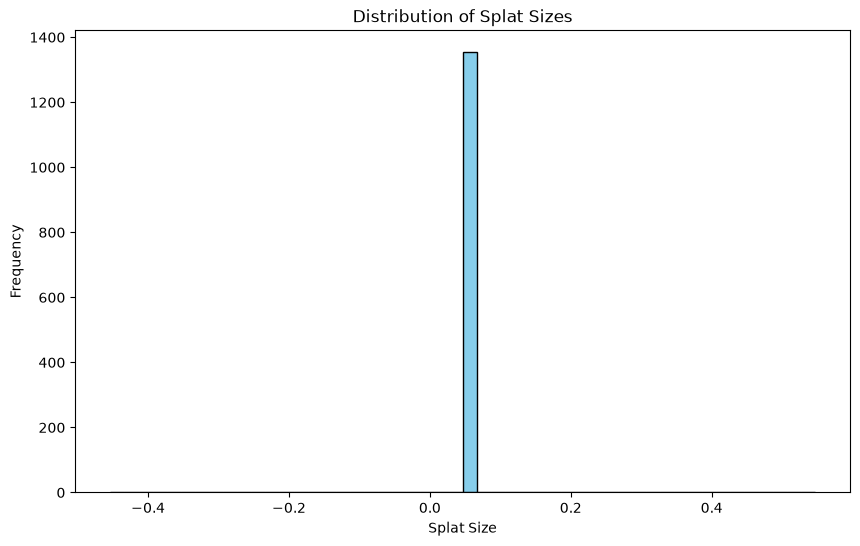

In [95]:
# read the splat sizes from the file
splat_sizes = []
with open(output_splat_sizes_filepath, 'r') as f:
    for line in f:
        splat_sizes.append(float(line.strip()))

# plot the splat sizes
plt.figure(figsize=(10, 6))
plt.hist(splat_sizes, bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Splat Sizes')
plt.xlabel('Splat Size')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Visualization of global and individual splats
plotter = pv.Plotter(shape=(1, 2))

plotter.subplot(0, 0)
plotter.add_text("Global splats", font_size=12)
mesh_io_data = meshio.read(output_folder + "splats_before.obj")
pv_mesh = pv.from_meshio(mesh_io_data)
plotter.add_mesh(pv_mesh, color='lightblue', show_edges=True)

plotter.subplot(0, 1)
plotter.add_text("Individual splats", font_size=12)
mesh_io_data = meshio.read(output_folder + "splats_individual.obj")
pv_mesh = pv.from_meshio(mesh_io_data)
plotter.add_mesh(pv_mesh, color='lightblue', show_edges=True)

plotter.link_views()
plotter.show()

Widget(value='<iframe src="http://localhost:35201/index.html?ui=P_0x70662f3e9160_0&reconnect=auto" class="pyvi…

In [97]:
mesh_io_data = meshio.read(input_mesh_filepath)

pv_mesh = pv.from_meshio(mesh_io_data)

plotter = pv.Plotter(notebook=True)
plotter.add_mesh(pv_mesh, color='lightblue', show_edges=True)
plotter.show()

Widget(value='<iframe src="http://localhost:44501/index.html?ui=P_0x70c0bc71f250_19&reconnect=auto" class="pyv…

In [14]:
mesh_io_data = meshio.read(output_mesh_filepath)

# 2. Convert it directly to a PyVista mesh object
pv_mesh = pv.from_meshio(mesh_io_data)

# 3. Setup the Jupyter backend & display interactively
pv.set_jupyter_backend('trame') # Options: 'trame' (highly interactive), or 'static'
plotter = pv.Plotter(notebook=True)
plotter.add_mesh(pv_mesh, color='lightblue', show_edges=True)
plotter.show()


Widget(value='<iframe src="http://localhost:46421/index.html?ui=P_0x771bf10d7250_2&reconnect=auto" class="pyvi…